In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    for filename in filenames[:5]:
        print(" -", filename)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sarifasiddikaa
/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer
 - ndb-ufes.csv
/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer/images
/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer/images/images
 - 0115.png
 - 0050.png
 - 0133.png
 - 0006.png
 - 0003.png


In [2]:
import pandas as pd

csv_path = '/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer/ndb-ufes.csv'
df = pd.read_csv(csv_path)

image_folders = ['/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer/images/images']

print("Total rows:", len(df))
print(df['diagnosis'].value_counts())

Total rows: 237
diagnosis
OSCC                             91
Leukoplakia with dysplasia       89
Leukoplakia without dysplasia    57
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

df = df.reset_index(drop=True)

sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(df, df['diagnosis'], groups=df['patient_id']))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf2.split(trainval_df, trainval_df['diagnosis'], groups=trainval_df['patient_id']))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

print("Overlap train-val:", len(set(train_df['patient_id']) & set(val_df['patient_id'])))
print("Overlap train-test:", len(set(train_df['patient_id']) & set(test_df['patient_id'])))
print("Overlap val-test:", len(set(val_df['patient_id']) & set(test_df['patient_id'])))

print("\nTrain:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))
print("Unique patients — Train:", train_df['patient_id'].nunique(), "Val:", val_df['patient_id'].nunique(), "Test:", test_df['patient_id'].nunique())

print("\nTrain label counts:")
print(train_df['diagnosis'].value_counts())
print("\nVal label counts:")
print(val_df['diagnosis'].value_counts())
print("\nTest label counts:")
print(test_df['diagnosis'].value_counts())

cat_cols = ['localization', 'tobacco_use', 'alcohol_consumption', 'sun_exposure', 'gender', 'skin_color']
numeric_cols = ['larger_size', 'age_group']

def encode_metadata(df, cat_cols, numeric_cols, reference_columns=None):
    df_cat = pd.get_dummies(df[cat_cols].astype(str))
    df_num = df[numeric_cols].fillna(df[numeric_cols].median())
    df_encoded = pd.concat([df_num, df_cat], axis=1)
    if reference_columns is not None:
        df_encoded = df_encoded.reindex(columns=reference_columns, fill_value=0)
    return df_encoded

full_encoded = encode_metadata(df, cat_cols, numeric_cols)
reference_columns = full_encoded.columns

train_meta = encode_metadata(train_df, cat_cols, numeric_cols, reference_columns=reference_columns)
val_meta = encode_metadata(val_df, cat_cols, numeric_cols, reference_columns=reference_columns)
test_meta = encode_metadata(test_df, cat_cols, numeric_cols, reference_columns=reference_columns)

le = LabelEncoder()
le.fit(train_df['diagnosis'])
train_labels = le.transform(train_df['diagnosis'])
val_labels = le.transform(val_df['diagnosis'])
test_labels = le.transform(test_df['diagnosis'])

train_df = train_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})
val_df = val_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})
test_df = test_df.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})

META_DIM = train_meta.shape[1]
print("\nMETA_DIM:", META_DIM)
print("Classes:", le.classes_)

Overlap train-val: 0
Overlap train-test: 0
Overlap val-test: 0

Train: 169 Val: 38 Test: 30
Unique patients — Train: 49 Val: 11 Test: 9

Train label counts:
diagnosis
Leukoplakia with dysplasia       68
OSCC                             65
Leukoplakia without dysplasia    36
Name: count, dtype: int64

Val label counts:
diagnosis
OSCC                             22
Leukoplakia without dysplasia    12
Leukoplakia with dysplasia        4
Name: count, dtype: int64

Test label counts:
diagnosis
Leukoplakia with dysplasia       17
Leukoplakia without dysplasia     9
OSCC                              4
Name: count, dtype: int64

META_DIM: 25
Classes: ['Leukoplakia with dysplasia' 'Leukoplakia without dysplasia' 'OSCC']


In [4]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import torchvision.models as models
import os

class SkinFusionDataset(Dataset):
    def __init__(self, df, meta_features, labels, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.meta_features = meta_features.reset_index(drop=True)
        self.labels = labels
        self.transform = transform
        self.image_lookup = {}
        for folder in image_folders:
            for fname in os.listdir(folder):
                self.image_lookup[fname] = os.path.join(folder, fname)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'img_id']
        img_path = self.image_lookup[img_name]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        meta = torch.tensor(self.meta_features.iloc[idx].values.astype('float32'))
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, meta, label

transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

image_folders = ['/kaggle/input/datasets/sarifasiddikaa/ndb-ufes-oral-cancer/images/images']

train_dataset = SkinFusionDataset(train_df, train_meta, train_labels, image_folders, train_transform)
val_dataset = SkinFusionDataset(val_df, val_meta, val_labels, image_folders, transform)
test_dataset = SkinFusionDataset(test_df, test_meta, test_labels, image_folders, transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, metas)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images, metas)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

class FusionModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(512+32, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        meta_feat = self.meta_branch(meta)
        return self.classifier(torch.cat([img_feat, meta_feat], dim=1))

class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta=None):
        return self.classifier(self.image_branch(image).flatten(1))

class MetaOnlyModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, num_classes))
    def forward(self, image, meta):
        return self.classifier(self.meta_branch(meta))

class MetaBlock(nn.Module):
    def __init__(self, image_feat_dim, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.meta_gate = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Sigmoid())
        self.meta_bias = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Tanh())
        self.classifier = nn.Sequential(nn.Linear(image_feat_dim, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        gate = self.meta_gate(meta)
        bias = self.meta_bias(meta)
        return self.classifier(img_feat * gate + bias)

import matplotlib.pyplot as plt

def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(train_loss, label='Train'); axes[0].plot(val_loss, label='Val')
    axes[0].set_title(f'{title} - Loss'); axes[0].legend()
    axes[1].plot(train_acc, label='Train'); axes[1].plot(val_acc, label='Val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/curve_{title}.png')
    plt.show()

print("All classes and functions defined")

All classes and functions defined


In [6]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

class_weights = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

model = FusionModel(meta_input_dim=META_DIM, num_classes=3).to(device)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

history_fusion = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(16):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history_fusion['train_loss'].append(train_loss); history_fusion['val_loss'].append(val_loss)
    history_fusion['train_acc'].append(train_acc); history_fusion['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/16 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_model_ndb.pth')
        print("  -> Saved new best model")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 155MB/s] 


Epoch 1/16 - Train loss: 1.0902, Train acc: 0.3846 - Val loss: 1.1066, Val acc: 0.2632
  -> Saved new best model
Epoch 2/16 - Train loss: 1.0953, Train acc: 0.3432 - Val loss: 1.1327, Val acc: 0.2632
Epoch 3/16 - Train loss: 1.0812, Train acc: 0.3787 - Val loss: 1.1245, Val acc: 0.3421
  -> Saved new best model
Epoch 4/16 - Train loss: 1.0654, Train acc: 0.4260 - Val loss: 1.1010, Val acc: 0.3421
Epoch 5/16 - Train loss: 1.0567, Train acc: 0.4556 - Val loss: 1.1040, Val acc: 0.3684
  -> Saved new best model
Epoch 6/16 - Train loss: 1.0462, Train acc: 0.4260 - Val loss: 1.0951, Val acc: 0.3684
Epoch 7/16 - Train loss: 1.0236, Train acc: 0.4970 - Val loss: 1.0955, Val acc: 0.3684
Epoch 8/16 - Train loss: 1.0418, Train acc: 0.4556 - Val loss: 1.1209, Val acc: 0.3684
Epoch 9/16 - Train loss: 1.0213, Train acc: 0.4911 - Val loss: 1.1331, Val acc: 0.3421
Epoch 10/16 - Train loss: 1.0104, Train acc: 0.5266 - Val loss: 1.1134, Val acc: 0.3421
Epoch 11/16 - Train loss: 1.0028, Train acc: 0.5444

Fusion Test acc: 0.5667


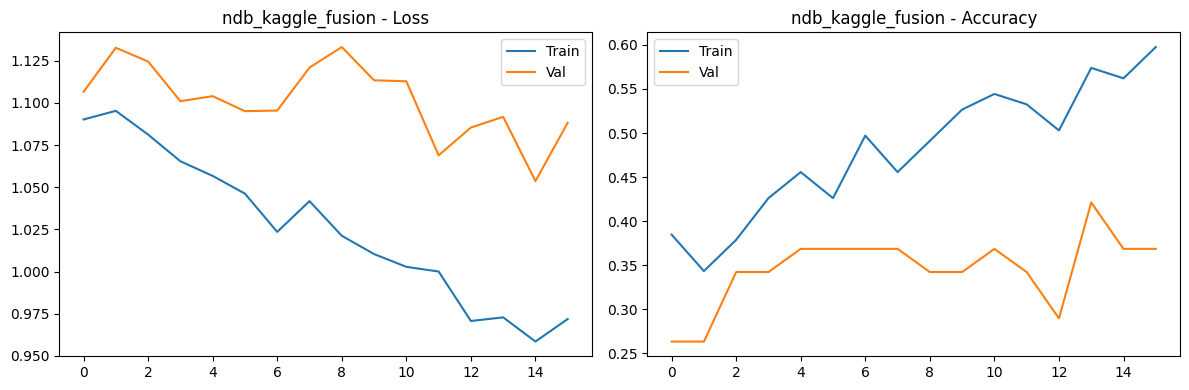

In [7]:
model.load_state_dict(torch.load('/kaggle/working/best_model_ndb.pth'))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Fusion Test acc: {test_acc:.4f}")

plot_curves(history_fusion['train_loss'], history_fusion['val_loss'], history_fusion['train_acc'], history_fusion['val_acc'], 'ndb_kaggle_fusion')

In [8]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

img_model = ImageOnlyModel(num_classes=3).to(device)
img_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_img = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(img_model, train_loader, criterion, img_optimizer, device)
    val_loss, val_acc = evaluate(img_model, val_loader, criterion, device)
    history_img['train_loss'].append(train_loss); history_img['val_loss'].append(val_loss)
    history_img['train_acc'].append(train_acc); history_img['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model.state_dict(), '/kaggle/working/best_image_only_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.1434, Train acc: 0.3314 - Val loss: 1.1416, Val acc: 0.1579
  -> Saved new best model
Epoch 2/15 - Train loss: 1.1114, Train acc: 0.2899 - Val loss: 1.0733, Val acc: 0.3684
  -> Saved new best model
Epoch 3/15 - Train loss: 1.0843, Train acc: 0.3373 - Val loss: 1.0806, Val acc: 0.3684
Epoch 4/15 - Train loss: 1.0866, Train acc: 0.3787 - Val loss: 1.0800, Val acc: 0.3947
  -> Saved new best model
Epoch 5/15 - Train loss: 1.0715, Train acc: 0.4734 - Val loss: 1.1102, Val acc: 0.3947
Epoch 6/15 - Train loss: 1.0770, Train acc: 0.4260 - Val loss: 1.1173, Val acc: 0.2632
Epoch 7/15 - Train loss: 1.0384, Train acc: 0.5207 - Val loss: 1.0810, Val acc: 0.4474
  -> Saved new best model
Epoch 8/15 - Train loss: 1.0295, Train acc: 0.4793 - Val loss: 1.0880, Val acc: 0.3158
Epoch 9/15 - Train loss: 1.0233, Train acc: 0.4734 - Val loss: 1.1131, Val acc: 0.2632
Epoch 10/15 - Train loss: 1.0222, Train acc: 0.5089 - Val loss: 1.0872, Val acc: 0.3158
Epoch 11/15 - Train loss:

Image-only Test acc: 0.4333


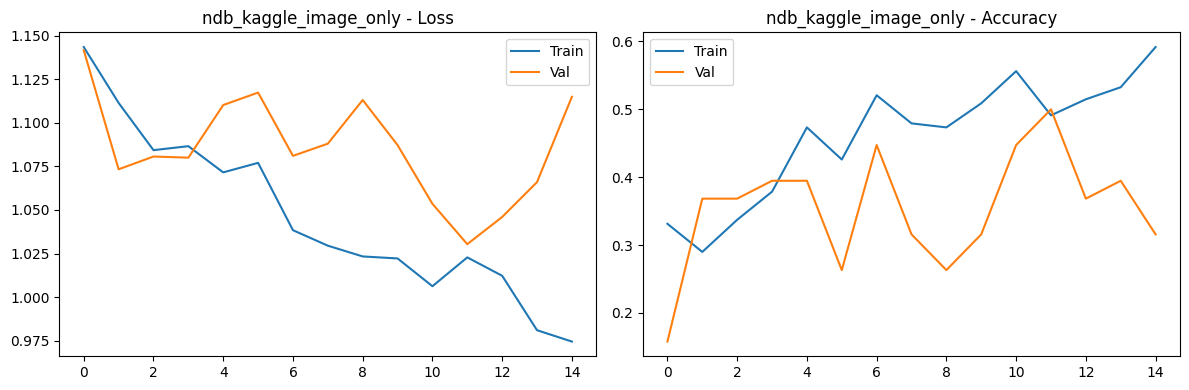

In [9]:
img_model.load_state_dict(torch.load('/kaggle/working/best_image_only_ndb.pth'))
test_loss, test_acc = evaluate(img_model, test_loader, criterion, device)
print(f"Image-only Test acc: {test_acc:.4f}")

plot_curves(history_img['train_loss'], history_img['val_loss'], history_img['train_acc'], history_img['val_acc'], 'ndb_kaggle_image_only')

In [10]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

meta_model = MetaOnlyModel(meta_input_dim=META_DIM, num_classes=3).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

history_meta = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    history_meta['train_loss'].append(train_loss); history_meta['val_loss'].append(val_loss)
    history_meta['train_acc'].append(train_acc); history_meta['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/kaggle/working/best_meta_only_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.1009, Train acc: 0.2426 - Val loss: 1.0929, Val acc: 0.3158
  -> Saved new best model
Epoch 2/15 - Train loss: 1.1022, Train acc: 0.2012 - Val loss: 1.0936, Val acc: 0.3158
Epoch 3/15 - Train loss: 1.0988, Train acc: 0.2308 - Val loss: 1.0945, Val acc: 0.3158
Epoch 4/15 - Train loss: 1.0976, Train acc: 0.2426 - Val loss: 1.0950, Val acc: 0.3158
Epoch 5/15 - Train loss: 1.0949, Train acc: 0.2485 - Val loss: 1.0956, Val acc: 0.3158
Epoch 6/15 - Train loss: 1.0984, Train acc: 0.2485 - Val loss: 1.0961, Val acc: 0.3158
Epoch 7/15 - Train loss: 1.0950, Train acc: 0.2485 - Val loss: 1.0968, Val acc: 0.3158
Epoch 8/15 - Train loss: 1.0988, Train acc: 0.2485 - Val loss: 1.0974, Val acc: 0.3158
Epoch 9/15 - Train loss: 1.0954, Train acc: 0.2899 - Val loss: 1.0980, Val acc: 0.2632
Epoch 10/15 - Train loss: 1.0938, Train acc: 0.2959 - Val loss: 1.0988, Val acc: 0.2632
Epoch 11/15 - Train loss: 1.0952, Train acc: 0.3195 - Val loss: 1.0994, Val acc: 0.2632
Epoch 12/15 - T

Meta-only Test acc: 0.3000


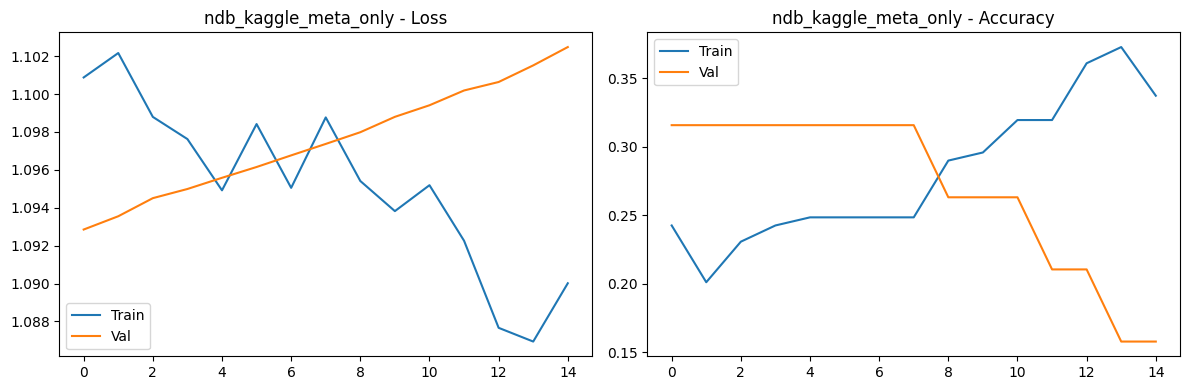

In [11]:
meta_model.load_state_dict(torch.load('/kaggle/working/best_meta_only_ndb.pth'))
test_loss, test_acc = evaluate(meta_model, test_loader, criterion, device)
print(f"Meta-only Test acc: {test_acc:.4f}")

plot_curves(history_meta['train_loss'], history_meta['val_loss'], history_meta['train_acc'], history_meta['val_acc'], 'ndb_kaggle_meta_only')

In [12]:
torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

metablock_model = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=3).to(device)
metablock_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_mb = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(20):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    history_mb['train_loss'].append(train_loss); history_mb['val_loss'].append(val_loss)
    history_mb['train_acc'].append(train_acc); history_mb['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/20 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/kaggle/working/best_metablock_ndb.pth')
        print("  -> Saved new best model")

Epoch 1/20 - Train loss: 1.1112, Train acc: 0.3669 - Val loss: 1.0773, Val acc: 0.5789
  -> Saved new best model
Epoch 2/20 - Train loss: 1.0587, Train acc: 0.5148 - Val loss: 1.0939, Val acc: 0.5000
Epoch 3/20 - Train loss: 1.0316, Train acc: 0.5740 - Val loss: 1.0816, Val acc: 0.3947
Epoch 4/20 - Train loss: 1.0359, Train acc: 0.5799 - Val loss: 1.0808, Val acc: 0.3947
Epoch 5/20 - Train loss: 1.0108, Train acc: 0.6213 - Val loss: 1.0957, Val acc: 0.3684
Epoch 6/20 - Train loss: 0.9882, Train acc: 0.6331 - Val loss: 1.0840, Val acc: 0.3684
Epoch 7/20 - Train loss: 0.9720, Train acc: 0.6627 - Val loss: 1.0811, Val acc: 0.4211
Epoch 8/20 - Train loss: 0.9471, Train acc: 0.6746 - Val loss: 1.0841, Val acc: 0.4211
Epoch 9/20 - Train loss: 0.9184, Train acc: 0.6864 - Val loss: 1.0749, Val acc: 0.4211
Epoch 10/20 - Train loss: 0.8804, Train acc: 0.7101 - Val loss: 1.0819, Val acc: 0.3947
Epoch 11/20 - Train loss: 0.8537, Train acc: 0.7515 - Val loss: 1.0848, Val acc: 0.4211
Epoch 12/20 - T

MetaBlock Test acc: 0.3000


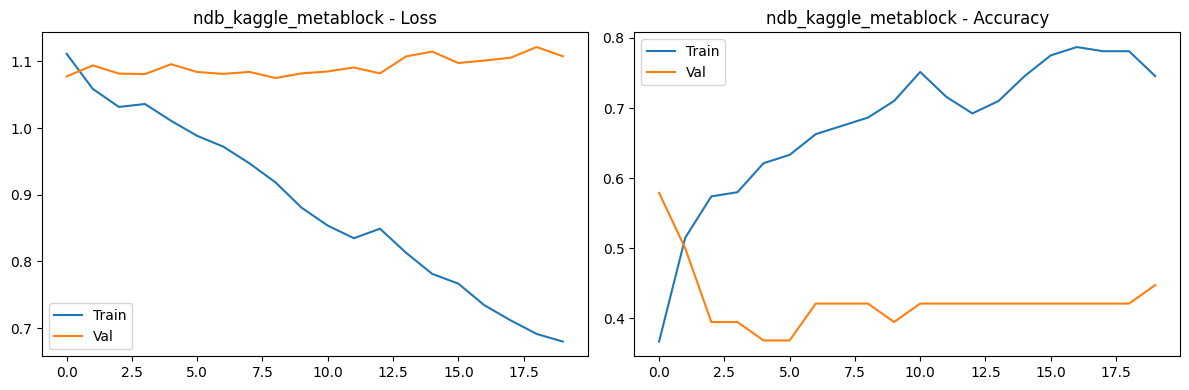

In [13]:
metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock_ndb.pth'))
test_loss, test_acc = evaluate(metablock_model, test_loader, criterion, device)
print(f"MetaBlock Test acc: {test_acc:.4f}")

plot_curves(history_mb['train_loss'], history_mb['val_loss'], history_mb['train_acc'], history_mb['val_acc'], 'ndb_kaggle_metablock')

In [14]:
from scipy.stats import spearmanr

model.load_state_dict(torch.load('/kaggle/working/best_model_ndb.pth'))

def compute_ablation_importance(model, loader, device):
    model.eval()
    results = {'true_label': [], 'baseline_prob': [], 'no_image_prob': [], 'no_meta_prob': [], 'none_prob': []}
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            baseline_out = torch.softmax(model(images, metas), dim=1)
            zero_images = torch.zeros_like(images)
            no_image_out = torch.softmax(model(zero_images, metas), dim=1)
            zero_metas = torch.zeros_like(metas)
            no_meta_out = torch.softmax(model(images, zero_metas), dim=1)
            none_out = torch.softmax(model(zero_images, zero_metas), dim=1)
            for i in range(labels.size(0)):
                label = labels[i].item()
                results['true_label'].append(label)
                results['baseline_prob'].append(baseline_out[i, label].item())
                results['no_image_prob'].append(no_image_out[i, label].item())
                results['no_meta_prob'].append(no_meta_out[i, label].item())
                results['none_prob'].append(none_out[i, label].item())
    return pd.DataFrame(results)

ablation_df_ndb = compute_ablation_importance(model, test_loader, device)
ablation_df_ndb['image_importance'] = ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_image_prob']
ablation_df_ndb['meta_importance'] = ablation_df_ndb['baseline_prob'] - ablation_df_ndb['no_meta_prob']
ablation_df_ndb['shapley_image'] = 0.5*(ablation_df_ndb['no_meta_prob']-ablation_df_ndb['none_prob']) + 0.5*(ablation_df_ndb['baseline_prob']-ablation_df_ndb['no_image_prob'])

corr_shap, p_shap = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['shapley_image'])
print(ablation_df_ndb[['image_importance','meta_importance']].describe())
print(f"\nAblation vs Shapley: rho={corr_shap:.3f}, p={p_shap:.4f}")

       image_importance  meta_importance
count         30.000000        30.000000
mean           0.021796        -0.000388
std            0.077135         0.001633
min           -0.188691        -0.002885
25%           -0.016794        -0.001654
50%            0.021482        -0.000380
75%            0.055191         0.000510
max            0.177351         0.003926

Ablation vs Shapley: rho=1.000, p=0.0000


In [15]:
!pip install captum -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.4 MB/s eta 0:00:00ta 0:00:01


In [16]:
from captum.attr import IntegratedGradients

def compute_ig_importance(model, loader, device):
    model.eval()
    ig_image_scores = []
    def forward_func(images, metas):
        return model(images, metas)
    ig = IntegratedGradients(forward_func)
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        images.requires_grad_()
        metas.requires_grad_()
        for i in range(labels.size(0)):
            attributions = ig.attribute((images[i:i+1], metas[i:i+1]), target=labels[i].item(), n_steps=20)
            img_attr, _ = attributions
            ig_image_scores.append(img_attr.abs().sum().item())
    return ig_image_scores

ig_image_ndb = compute_ig_importance(model, test_loader, device)
ablation_df_ndb['ig_image'] = ig_image_ndb

corr_ig, p_ig = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['ig_image'])
print(f"Ablation vs IG: rho={corr_ig:.3f}, p={p_ig:.4f}")

Ablation vs IG: rho=0.180, p=0.3413


In [17]:
def make_truly_random_model(meta_input_dim, num_classes):
    m = FusionModel(meta_input_dim=meta_input_dim, num_classes=num_classes)
    for module in m.image_branch.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return m.to(device)

random_model_ndb = make_truly_random_model(meta_input_dim=META_DIM, num_classes=3)
random_ig_image_ndb = compute_ig_importance(random_model_ndb, test_loader, device)

corr_sanity, p_sanity = spearmanr(ig_image_ndb, random_ig_image_ndb)
print(f"Trained-IG vs Random-IG: rho={corr_sanity:.3f}, p={p_sanity:.4f}")

Trained-IG vs Random-IG: rho=0.371, p=0.0434


In [18]:
def compute_gate_importance(mb_model, loader, device):
    mb_model.eval()
    gate_scores = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            gate = mb_model.meta_gate(metas)
            gate_scores.extend(gate.mean(dim=1).cpu().numpy())
    return gate_scores

gate_scores_ndb = compute_gate_importance(metablock_model, test_loader, device)
ablation_df_ndb['gate_image'] = gate_scores_ndb

corr_gate, p_gate = spearmanr(ablation_df_ndb['image_importance'], ablation_df_ndb['gate_image'])
print(f"Ablation vs Gate: rho={corr_gate:.3f}, p={p_gate:.4f}")
print(ablation_df_ndb['gate_image'].describe())

Ablation vs Gate: rho=-0.271, p=0.1481
count    30.000000
mean      0.503184
std       0.001421
min       0.500424
25%       0.502357
50%       0.503201
75%       0.504812
max       0.504865
Name: gate_image, dtype: float64


In [19]:
ablation_df_ndb['rank_ablation'] = ablation_df_ndb['image_importance'].rank()
ablation_df_ndb['rank_ig'] = ablation_df_ndb['ig_image'].rank()
ablation_df_ndb['rank_gate'] = ablation_df_ndb['gate_image'].rank()
ablation_df_ndb['ig_disagreement'] = (ablation_df_ndb['rank_ablation'] - ablation_df_ndb['rank_ig']).abs()
ablation_df_ndb['gate_disagreement'] = (ablation_df_ndb['rank_ablation'] - ablation_df_ndb['rank_gate']).abs()

print("Top IG disagreement (NDB-UFES Kaggle):")
print(ablation_df_ndb.nlargest(3, 'ig_disagreement')[['true_label','rank_ablation','rank_ig','image_importance','ig_image']])

print("\nTop Gate disagreement (NDB-UFES Kaggle):")
print(ablation_df_ndb.nlargest(3, 'gate_disagreement')[['true_label','rank_ablation','rank_gate','image_importance','gate_image']])

Top IG disagreement (NDB-UFES Kaggle):
    true_label  rank_ablation  rank_ig  image_importance    ig_image
3            1           26.0      3.0          0.073261  132.252411
28           0            5.0     28.0         -0.040758  247.104645
6            1           28.0      8.0          0.152387  149.989502

Top Gate disagreement (NDB-UFES Kaggle):
    true_label  rank_ablation  rank_gate  image_importance  gate_image
19           0            1.0       29.0         -0.188691    0.504865
25           0            2.0       24.5         -0.114750    0.504812
6            1           28.0        7.0          0.152387    0.502357


In [20]:
from sklearn.metrics import classification_report

def get_report(model, loader, device, class_names, is_image_only=False):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images) if is_image_only else model(images, metas)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

model.load_state_dict(torch.load('/kaggle/working/best_model_ndb.pth'))
print("Fusion:")
get_report(model, test_loader, device, le.classes_)

img_model.load_state_dict(torch.load('/kaggle/working/best_image_only_ndb.pth'))
print("\nImage-only:")
get_report(img_model, test_loader, device, le.classes_, is_image_only=True)

meta_model.load_state_dict(torch.load('/kaggle/working/best_meta_only_ndb.pth'))
print("\nMeta-only:")
get_report(meta_model, test_loader, device, le.classes_)

metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock_ndb.pth'))
print("\nMetaBlock:")
get_report(metablock_model, test_loader, device, le.classes_)

Fusion:
                               precision    recall  f1-score   support

   Leukoplakia with dysplasia       0.63      0.71      0.67        17
Leukoplakia without dysplasia       0.29      0.22      0.25         9
                         OSCC       0.75      0.75      0.75         4

                     accuracy                           0.57        30
                    macro avg       0.56      0.56      0.56        30
                 weighted avg       0.54      0.57      0.55        30


Image-only:
                               precision    recall  f1-score   support

   Leukoplakia with dysplasia       0.50      0.06      0.11        17
Leukoplakia without dysplasia       0.38      0.89      0.53         9
                         OSCC       0.57      1.00      0.73         4

                     accuracy                           0.43        30
                    macro avg       0.48      0.65      0.46        30
                 weighted avg       0.47      0.43 

In [21]:
from sklearn.model_selection import StratifiedGroupKFold

results_10runs_ndb_v2 = []

for seed in range(1, 11):
    print(f"\n===== SEED {seed} (new split + new weights) =====")
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Redraw a fresh patient-level split for this seed
    sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    trainval_idx, test_idx = next(sgkf1.split(df, df['diagnosis'], groups=df['patient_id']))
    trainval_df_s = df.iloc[trainval_idx].reset_index(drop=True)
    test_df_s = df.iloc[test_idx].reset_index(drop=True)

    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    train_idx, val_idx = next(sgkf2.split(trainval_df_s, trainval_df_s['diagnosis'], groups=trainval_df_s['patient_id']))
    train_df_s = trainval_df_s.iloc[train_idx].reset_index(drop=True)
    val_df_s = trainval_df_s.iloc[val_idx].reset_index(drop=True)

    train_meta_s = encode_metadata(train_df_s, cat_cols, numeric_cols, reference_columns=reference_columns)
    test_meta_s = encode_metadata(test_df_s, cat_cols, numeric_cols, reference_columns=reference_columns)

    le_s = LabelEncoder()
    le_s.fit(train_df_s['diagnosis'])
    train_labels_s = le_s.transform(train_df_s['diagnosis'])
    test_labels_s = le_s.transform(test_df_s['diagnosis'])

    train_df_s = train_df_s.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})
    test_df_s = test_df_s.rename(columns={'path': 'img_id', 'diagnosis': 'diagnostic'})

    train_dataset_s = SkinFusionDataset(train_df_s, train_meta_s, train_labels_s, image_folders, train_transform)
    test_dataset_s = SkinFusionDataset(test_df_s, test_meta_s, test_labels_s, image_folders, transform)
    train_loader_s = DataLoader(train_dataset_s, batch_size=16, shuffle=True, num_workers=2)
    test_loader_s = DataLoader(test_dataset_s, batch_size=16, shuffle=False, num_workers=2)

    class_weights_s = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels_s), y=train_labels_s), dtype=torch.float32).to(device)
    criterion_s = nn.CrossEntropyLoss(weight=class_weights_s)

    m = FusionModel(meta_input_dim=META_DIM, num_classes=3).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(16):
        train_one_epoch(m, train_loader_s, criterion_s, opt, device)

    mb = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=3).to(device)
    mb_opt = torch.optim.Adam(filter(lambda p: p.requires_grad, mb.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(20):
        train_one_epoch(mb, train_loader_s, criterion_s, mb_opt, device)

    adf = compute_ablation_importance(m, test_loader_s, device)
    adf['image_importance'] = adf['baseline_prob'] - adf['no_image_prob']
    adf['shapley_image'] = 0.5*(adf['no_meta_prob']-adf['none_prob']) + 0.5*(adf['baseline_prob']-adf['no_image_prob'])

    ig_scores = compute_ig_importance(m, test_loader_s, device)
    adf['ig_image'] = ig_scores

    gate_scores = compute_gate_importance(mb, test_loader_s, device)
    adf['gate_image'] = gate_scores

    rho_shap, _ = spearmanr(adf['image_importance'], adf['shapley_image'])
    rho_ig, _ = spearmanr(adf['image_importance'], adf['ig_image'])
    rho_gate, _ = spearmanr(adf['image_importance'], adf['gate_image'])

    _, fusion_test_acc = evaluate(m, test_loader_s, criterion_s, device)
    _, mb_test_acc = evaluate(mb, test_loader_s, criterion_s, device)

    results_10runs_ndb_v2.append({
        'seed': seed, 'rho_shapley': rho_shap, 'rho_ig': rho_ig, 'rho_gate': rho_gate,
        'fusion_acc': fusion_test_acc, 'metablock_acc': mb_test_acc
    })
    print(f"rho_shapley={rho_shap:.3f}, rho_ig={rho_ig:.3f}, rho_gate={rho_gate:.3f}, fusion_acc={fusion_test_acc:.3f}, mb_acc={mb_test_acc:.3f}")

results_df_ndb_v2 = pd.DataFrame(results_10runs_ndb_v2)
print("\n===== SUMMARY (mean ± std across 10 different splits+seeds, NDB-UFES) =====")
print(results_df_ndb_v2[['rho_shapley', 'rho_ig', 'rho_gate', 'fusion_acc', 'metablock_acc']].agg(['mean', 'std']))

results_df_ndb_v2.to_csv('/kaggle/working/10run_results_ndb_v2.csv', index=False)


===== SEED 1 (new split + new weights) =====
rho_shapley=1.000, rho_ig=0.072, rho_gate=0.437, fusion_acc=0.479, mb_acc=0.583

===== SEED 2 (new split + new weights) =====
rho_shapley=0.999, rho_ig=0.270, rho_gate=0.289, fusion_acc=0.750, mb_acc=0.786

===== SEED 3 (new split + new weights) =====
rho_shapley=1.000, rho_ig=-0.309, rho_gate=0.009, fusion_acc=0.333, mb_acc=0.718

===== SEED 4 (new split + new weights) =====
rho_shapley=1.000, rho_ig=0.064, rho_gate=-0.011, fusion_acc=0.500, mb_acc=0.676

===== SEED 5 (new split + new weights) =====
rho_shapley=0.998, rho_ig=0.248, rho_gate=-0.019, fusion_acc=0.350, mb_acc=0.600

===== SEED 6 (new split + new weights) =====
rho_shapley=1.000, rho_ig=0.146, rho_gate=-0.129, fusion_acc=0.459, mb_acc=0.649

===== SEED 7 (new split + new weights) =====
rho_shapley=0.998, rho_ig=0.026, rho_gate=0.223, fusion_acc=0.594, mb_acc=0.531

===== SEED 8 (new split + new weights) =====
rho_shapley=0.999, rho_ig=-0.326, rho_gate=-0.027, fusion_acc=0.412,